In [1]:
from collections import defaultdict
from tqdm.notebook import tqdm

import numpy

from scipy.stats import gaussian_kde
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score
)
import torch

from datasets import (
    DatasetDict,
    Dataset,
    load_dataset,
    Features,
    Sequence,
    Value,
    Array2D
)

from robat.models import RoBaTForTrajectoryPrediction, RoBaTConfig
from robat.datasets.ds_preprocess import (
    ds_preprocess_for_eval
)

from accelerate import Accelerator

from matplotlib import pyplot

In [2]:
model = RoBaTForTrajectoryPrediction.from_pretrained(
    "Junhyeong86/battery-health-prediction-model",
    subfolder="trajectory-prediction",
)

In [3]:
ds = ds_preprocess_for_eval(
    ds_name="Junhyeong86/battery-health-prediction",
    model_purpose="trajectory_prediction",
    random_time_len=model.config.random_time_len,
    split_cycle_len=256,
    eval_ds_column="test",
    trajectory_pred_len=model.config.ode_prediction_len
)

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

... (164 outputs left out)

Casting the dataset:   0%|          | 0/8 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/9 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/9 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/9 [00:00<?, ? examples/s]

In [47]:
accelerator = Accelerator()
model = accelerator.prepare(model)
model.eval()
progress_bar = tqdm(total=len(ds), desc="Evaluating")
overall_label_and_pred = defaultdict(lambda: defaultdict(list))
for cell_id, data in ds.items():
    ref = cell_id.split("/")[0]
    progress_bar.set_postfix({"processing cell id": cell_id})
    inp = {
        "first_discharge_capacity": data["first_discharge_capacity"],
        "state_of_health": data["state_of_health"],
        "time": data["time"],
        "voltage_per_time": data["voltage_per_time"],
        "current_per_time": data["current_per_time"],
        "mask": data["mask"],
        "label_discharge_capacity": data["label_discharge_capacity"],
        "label_state_of_health": data["label_state_of_health"],
    }
    inp = {k: v.to(accelerator.device) for k, v in inp.items()}
    with torch.no_grad():
        pred = model(**inp)
    cycle_idx = data["cycle_idx"].detach().cpu().numpy()
    mask = cycle_idx == model.config.padding_value
    pred_discharge_capacity = (
        pred.discharge_capacity
        .detach()
        .cpu()
        .numpy()
    )
    label_discharge_capacity = (
        data["label_discharge_capacity"]
        .detach()
        .cpu()
        .numpy()
    )
    state_of_health = (
        data["state_of_health"]
        .detach()
        .cpu()
        .numpy()
    )
    first_discharge_capacity = (
        data["first_discharge_capacity"]
        .detach()
        .cpu()
        .numpy()
    )
    known_discharge_capacity = state_of_health.copy()
    known_discharge_capacity[~mask] = (known_discharge_capacity * first_discharge_capacity.reshape(-1, 1))[~mask]
    overall_label_and_pred[ref]["cell_id"].append(cell_id)
    overall_label_and_pred[ref]["cycle_idx"].append(cycle_idx)
    overall_label_and_pred[ref]["known_discharge_capacity"].append(known_discharge_capacity)
    overall_label_and_pred[ref]["pred_discharge_capacity"].append(pred_discharge_capacity)
    overall_label_and_pred[ref]["label_discharge_capacity"].append(label_discharge_capacity)
    progress_bar.update(1)
progress_bar.close()

Evaluating:   0%|          | 0/58 [00:00<?, ?it/s]

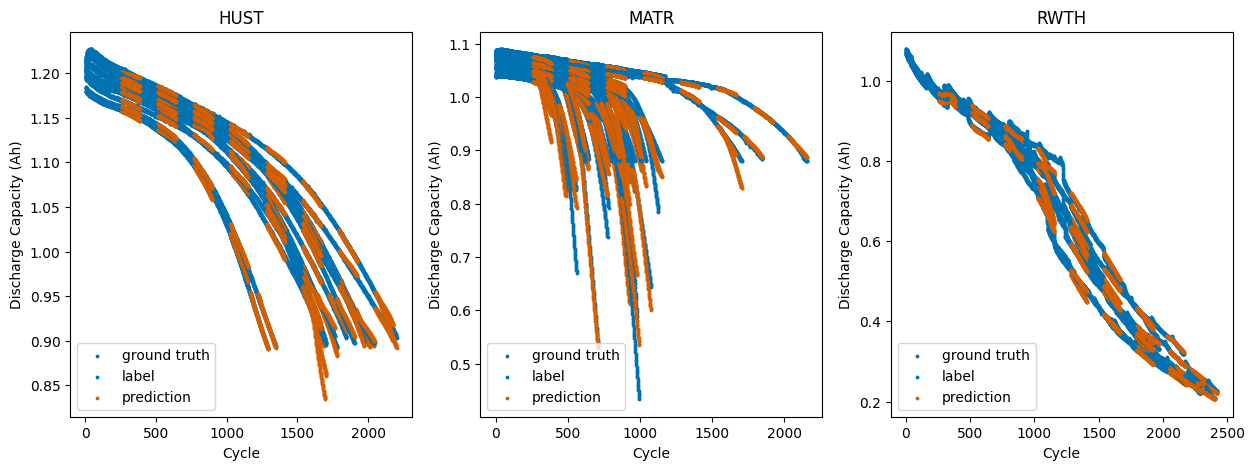

In [111]:
fig, axes = pyplot.subplots(1, len(overall_label_and_pred), figsize=(15, 5))

for ax, (ref, data) in zip(axes, overall_label_and_pred.items()):
    ax.set_title(ref)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Discharge Capacity (Ah)")

    ref_iterator = zip(
        data["cycle_idx"],
        data["known_discharge_capacity"],
        data["pred_discharge_capacity"],
        data["label_discharge_capacity"],
    )
    for ref_iter in ref_iterator:
        (
            cycle_idx,
            known_discharge_capacity,
            pred_discharge_capacity,
            label_discharge_capacity
        ) = ref_iter
        pred_discharge_capacity_cycle_idx = numpy.tile(
            numpy.arange(pred_discharge_capacity.shape[1]),
            (len(cycle_idx), 1)
        ) + cycle_idx[:, -1].reshape(-1, 1)
        mask = cycle_idx == model.config.padding_value
        ax.scatter(
            cycle_idx[~mask],
            known_discharge_capacity[~mask],
            c="#0072B2",
            label="ground truth",
            marker="o",
            s=3,
            zorder=2
        )
        ax.scatter(
            pred_discharge_capacity_cycle_idx.reshape(-1, ),
            label_discharge_capacity.reshape(-1, ),
            c="#0072B2",
            label="label",
            marker="o",
            s=3,
            zorder=2
        )
        ax.scatter(
            pred_discharge_capacity_cycle_idx.reshape(-1, ),
            pred_discharge_capacity.reshape(-1, ),
            c="#D55E00",
            label="prediction",
            marker="o",
            s=3,
            zorder=2
        )
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc="lower left")
pyplot.show()

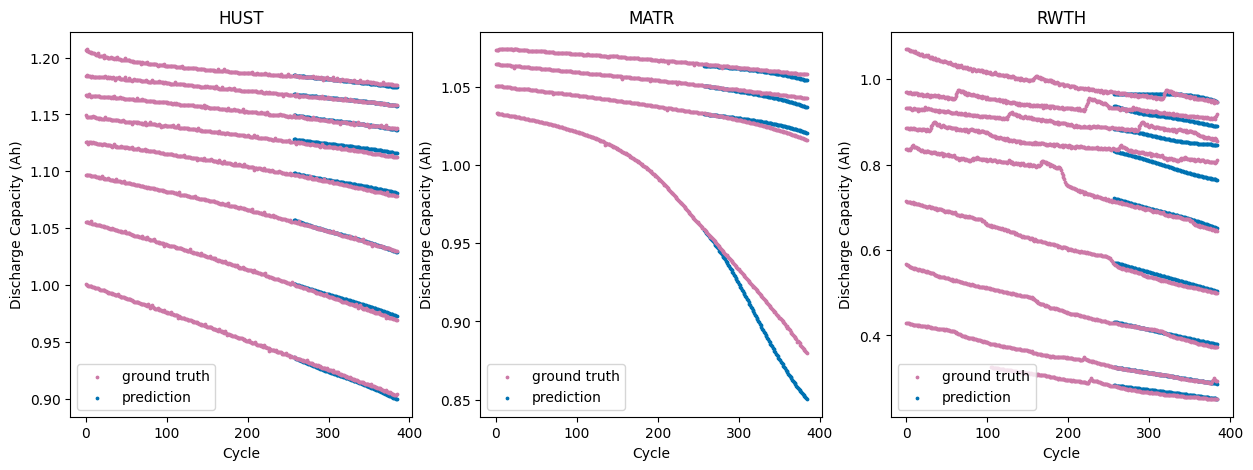

In [93]:
fig, axes = pyplot.subplots(1, len(overall_label_and_pred), figsize=(15, 5))

for ax, (ref, data) in zip(axes, overall_label_and_pred.items()):
    ax.set_title(ref)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Discharge Capacity (Ah)")

    ref_iterator = zip(
        data["cycle_idx"],
        data["known_discharge_capacity"],
        data["pred_discharge_capacity"],
        data["label_discharge_capacity"],
    )
    for ref_iter in ref_iterator:
        (
            cycle_idx,
            known_discharge_capacity,
            pred_discharge_capacity,
            label_discharge_capacity
        ) = ref_iter
        mask = cycle_idx == model.config.padding_value
        batch_size, split_cycle_len = known_discharge_capacity.shape
        plot_cycle_idx = numpy.tile(numpy.arange(split_cycle_len), (batch_size, 1))
        pred_discharge_capacity_cycle_idx = numpy.tile(
            numpy.arange(model.config.ode_prediction_len),
            (batch_size, 1)
        ) + split_cycle_len + 1
        ax.scatter(
            plot_cycle_idx[~mask],
            known_discharge_capacity[~mask],
            c="#CC79A7",
            label="ground truth",
            marker="o",
            s=3,
            zorder=2,
        )
        ax.scatter(
            pred_discharge_capacity_cycle_idx.reshape(-1, ),
            label_discharge_capacity.reshape(-1, ),
            c="#CC79A7",
            label="ground truth",
            marker="o",
            s=3,
            zorder=2
        )
        ax.scatter(
            pred_discharge_capacity_cycle_idx.reshape(-1, ),
            pred_discharge_capacity.reshape(-1, ),
            c="#0072B2",
            label="prediction",
            marker="o",
            s=3,
            zorder=1
        )
        break
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc="lower left")
pyplot.show()

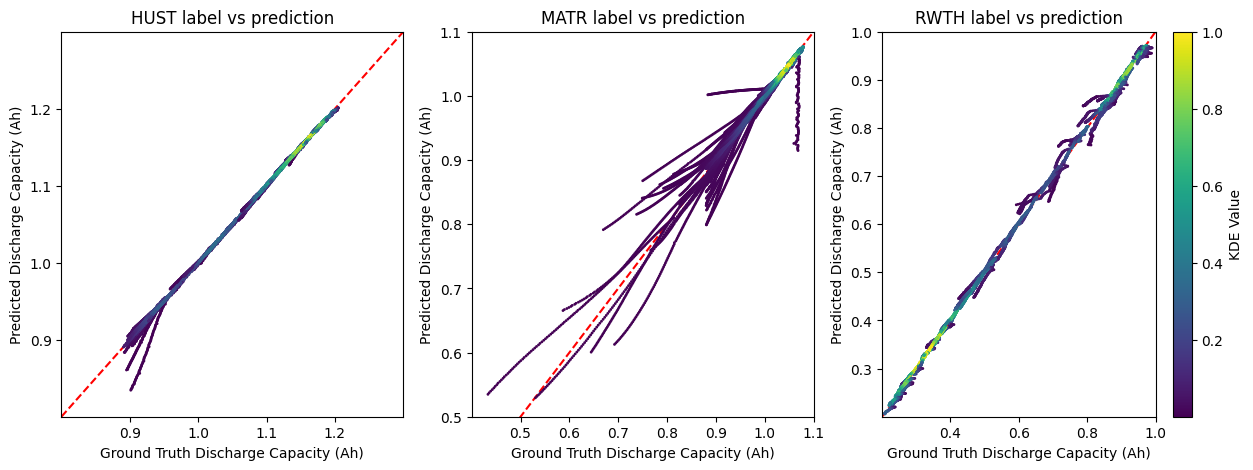

In [94]:
get_xrange = lambda x: (
    numpy.floor(x.min() * 10) / 10,
    numpy.ceil(x.max() * 10) / 10
)

fig, axes = pyplot.subplots(1, len(overall_label_and_pred), figsize=(15, 5))

for ax, (ref, data) in zip(axes, overall_label_and_pred.items()):
    ax.set_title(ref)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Discharge Capacity (Ah)")

    pred = numpy.concatenate(data["pred_discharge_capacity"], axis=0).reshape(-1, )
    label = numpy.concatenate(data["label_discharge_capacity"], axis=0).reshape(-1, )
    label_and_pred = numpy.vstack((label, pred))
    kde = gaussian_kde(label_and_pred)
    kde_values = kde(label_and_pred)
    kde_values = kde_values / kde_values.max()  # Normalize KDE values for better visualization
    sc = ax.scatter(
        label_and_pred[0],
        label_and_pred[1],
        c=kde_values,
        cmap="viridis",
        s=1,
        zorder=2,
    )
    xrange = get_xrange(label_and_pred[0])
    yrange = get_xrange(label_and_pred[1])
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.plot(
        xrange,
        xrange,
        c="red",
        linestyle="--",
        label="y=x",
        zorder=1,
    )
    ax.set_title(f"{ref} label vs prediction")
    ax.set_xlabel("Ground Truth Discharge Capacity (Ah)")
    ax.set_ylabel("Predicted Discharge Capacity (Ah)")
fig.colorbar(sc, ax=ax, label="KDE Value")
pyplot.show()

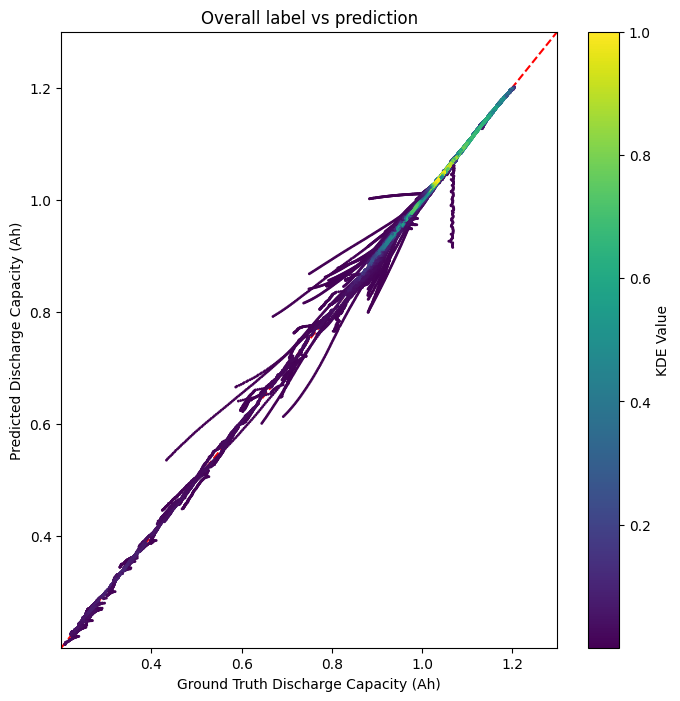

In [108]:
fig, ax = pyplot.subplots(figsize=(8, 8))

pred = numpy.concatenate([
    numpy.concatenate(data["pred_discharge_capacity"])
    for data in overall_label_and_pred.values()
]).reshape(-1, )
label = numpy.concatenate([
    numpy.concatenate(data["label_discharge_capacity"])
    for data in overall_label_and_pred.values()
]).reshape(-1, )
label_and_pred = numpy.vstack((label, pred))
kde = gaussian_kde(label_and_pred)
kde_values = kde(label_and_pred)
kde_values = kde_values / kde_values.max()  # Normalize KDE values for better visualization

sc = ax.scatter(
    label_and_pred[0],
    label_and_pred[1],
    c=kde_values,
    cmap="viridis",
    s=1,
    zorder=2,
)
xrange = get_xrange(label_and_pred[0])
yrange = get_xrange(label_and_pred[1])
ax.set_xlim(xrange)
ax.set_ylim(yrange)
ax.plot(
    xrange,
    xrange,
    c="red",
    linestyle="--",
    label="y=x",
    zorder=1,
)
ax.set_title("Overall label vs prediction")
ax.set_xlabel("Ground Truth Discharge Capacity (Ah)")
ax.set_ylabel("Predicted Discharge Capacity (Ah)")

fig.colorbar(sc, ax=ax, label="KDE Value")
pyplot.show()

In [109]:
rmse = root_mean_squared_error(label, pred) * 1e3  # Convert to mAh
mae = mean_absolute_error(label, pred) * 1e3  # Convert to mAh
r2 = r2_score(label, pred) * 100  # Convert to percentage
print(
    f"RMSE: {rmse:.4f} mAh\n"
    f"MAE: {mae:.4f} mAh\n"
    f"R2: {r2:.4f} %"
)

RMSE: 12.8220 mAh
MAE: 5.4036 mAh
R2: 99.7079 %
